## 지난주 개념 복습!
아래 마크다운을 풀고, 지난주 예습과제를 통해 공부한 Vision Transformer의 특징과 다른 모델들과의 차이점을 간략히 설명해주세요.

- 이미지를 패치 단오로 바꿔 읽는다: ViT는 이미지를 16x16 크기의 작은 조각(패치)으로 자르고, 각 패치를 한 줄로 펴서 벡터(임베딩)으로 만든 뒤, NLP의 Transformer가 단어를 읽듯 패치들의 나열(시퀀스)로 처리한다. 맨 앞에 분류용 [CLS]토큰을 붙이고, 패치의 위치 정보는 위치 임베딩(position embedding)으로 더해준다.
- Self-Attention으로 처음부터 전체를 본다: 모든 패치가 다른 모든 패치와 서로 얼마나 관련 있는지 (attention)를 계산하므로, 첫 층부터 이미지 전체의 관계(전역 정보)를 볼 수 있다. 마지막에는 [CLS]토큰의 출력에 MLP Head를 달아 클래스를 예측한다.
-CNN과의 차이: CNN은 작은 필터를 밀어가며 가까운 픽셀끼리 관련 있다(지역성), 물체가 어디 있든 같은 특징이다(이동 불변성)이라는 가정(귀납적 편향, inductive bias)을 구조에 미리 넣어 두고, 층을 쌓으며 보는 범위(수용 영역)을 점점 넓힌다. ViT는 이런 가정이 거의 없어 더 유연하지만, 그만큼 데이타로 직접 배워야하므로 작은 데이터셋에서는 불리하고, 대규모 데이터로 사전학습한 뒤 미세조정 할 때 CNN을 능가한다.
-RNN/기존 Transformer와의 차이: RNN처럼 순서대로 하나씩 처리하지 않고 모든 패치를 한 번에 병렬 처리한다. 구조는 NLP Transformer의 인코더를 거의 그대로 가져왔고, 입력만 단어 토큰 대신 이미지 패치로 바꾼 것이다.

## 파이토치로 구현한 Vision Transformer
이번 복습과제에서는 카사바 잎 질병 데이터셋으로 vision transformer를 학습시키겠습니다.
- 첨부된 드라이브에서 필요한 파일들을 다운받을 수 있습니다.

In [2]:
!pip install timm

In [3]:
!pip uninstall -y torch-tpu

### 데이터 불러오기

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
!ls -la /content/drive/MyDrive/week9/

total 2814802
dr-x------ 1 root root       4096 Apr 13  2026 .
dr-x------ 2 root root       4096 Apr 13  2026 ..
-r-------- 1 root root  321438207 Apr 13  2026 jx_vit_base_p16_224-80ecf9dd.pth.zip
-r-------- 1 root root     144281 Apr 13  2026 test.jpg
-r-------- 1 root root     358283 Apr 13  2026 train.csv
-r-------- 1 root root 2560407543 Apr 13  2026 train_images.zip


In [6]:
#.zip 파일 unzip
#본인 드라이브의 경로에 맞게 수정해주세요!
!mkdir -p /content/mydata
!cp /content/drive/MyDrive/week9/train.csv /content/drive/MyDrive/week9/test.jpg /content/mydata/
!unzip -q /content/drive/MyDrive/week9/train_images.zip -d /content/mydata/

In [7]:
#파일 경로
DATA_PATH = "/content/mydata/"
TRAIN_PATH = "/content/mydata/train_images"
TEST_PATH = "/content/mydata/test.jpg"
MODEL_PATH = (
    "/content/mydata/jx_vit_base_p16_224-80ecf9dd.pth"
)

### 라이브러리

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("ggplot")

import torch
import torch.nn as nn
import torchvision.transforms as transforms

#import torch_xla
#import torch_xla.core.xla_model as xm
#import torch_xla.distributed.xla_multiprocessing as xmp
#import torch_xla.distributed.parallel_loader as pl

import timm

import gc
import os
import time
import random
from datetime import datetime

from PIL import Image
from tqdm.notebook import tqdm
from sklearn import model_selection, metrics

In [9]:
!mkdir -p /content/mydata/train_images
!find /content/mydata -maxdepth 1 -name "*.jpg" ! -name "test.jpg" -exec mv {} /content/mydata/train_images/ \;
!ls /content/mydata
!ls /content/mydata/train_images | wc -l

test.jpg  train.csv  train_images
21397


In [10]:
!cp /content/drive/MyDrive/week9/jx_vit_base_p16_224-80ecf9dd* /content/mydata/
!cd /content/mydata && for f in jx_vit*.zip; do [ -e "$f" ] && unzip -q -o "$f"; done
!ls /content/mydata

jx_vit_base_p16_224-80ecf9dd.pth      test.jpg	 train_images
jx_vit_base_p16_224-80ecf9dd.pth.zip  train.csv


In [11]:
os.environ["XLA_USE_BF16"] = "1"
os.environ["XLA_TENSOR_ALLOCATOR_MAXSIZE"] = "100000000"

In [12]:
def seed_everything(seed):
    """
    Seeds basic parameters for reproductibility of results

    Arguments:
        seed {int} -- Number of the seed
    """
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(1001)

### 파라미터

In [13]:
IMG_SIZE = 224  #ViT에 적합한 이미지 크기로 설정해주세요.
BATCH_SIZE = 16
LR = 2e-05
GAMMA = 0.7
N_EPOCHS = 1  #모델 학습을 위해서는 더 많은 에포크가 필요하지만, 파일 크기가 큰 관계로 이번 과제에서는 전 과정을 한 번만 수행하겠습니다.

In [14]:
# pandas로 csv 파일을 읽은 뒤, 첫 5행을 출력하세요.
df = pd.read_csv(os.path.join(DATA_PATH, "train.csv"))
df.head()

,image_id,label
0,1000015157.jpg,0
1,1000201771.jpg,3
2,100042118.jpg,1
3,1000723321.jpg,1
4,1000812911.jpg,3


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21397 entries, 0 to 21396
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image_id  21397 non-null  object
 1   label     21397 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 334.5+ KB


<Axes: xlabel='label'>

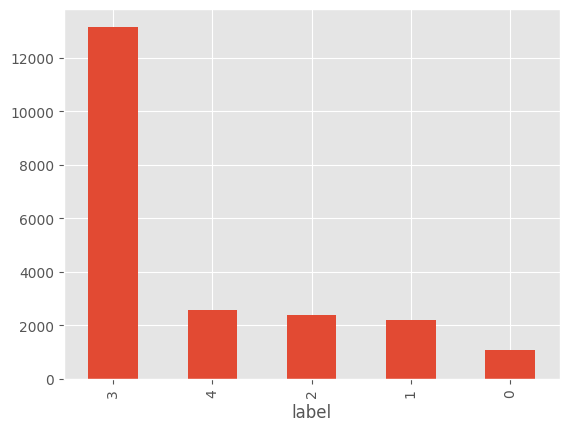

In [16]:
df.label.value_counts().plot(kind="bar")

In [17]:
# train과 test를 9:1로 나눠주세요.
# random_state은 자유롭게 지정 가능합니다.
train_df, valid_df = model_selection.train_test_split(
    df, test_size=0.1, random_state=42, stratify=df.label.values
)

In [18]:
class CassavaDataset(torch.utils.data.Dataset):

    def __init__(self, df, data_path=DATA_PATH, mode="train", transforms=None):
        super().__init__()
        self.df_data = df.values
        self.data_path = data_path
        self.transforms = transforms
        self.mode = mode
        self.data_dir = "train_images" if mode == "train" else "test_images"

    def __len__(self):
        return len(self.df_data)

    def __getitem__(self, index):
        img_name, label = self.df_data[index]
        img_path = os.path.join(self.data_path, self.data_dir, img_name)
        img = Image.open(img_path).convert("RGB")

        if self.transforms is not None:
            image = self.transforms(img)

        return image, label

In [19]:
#데이터 증강
transforms_train = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(p=0.3),
        transforms.RandomResizedCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ]
)

transforms_valid = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ]
)

In [20]:
#사용 가능한 ViT 모델 목록
##우리는 이중 vit_base_patch16_224를 사용합니다!
print("Available Vision Transformer Models: ")
timm.list_models("vit*")

Available Vision Transformer Models: 


['vit_5b_patch16_sapiens2',
 'vit_7b_patch16_dinov3',
 'vit_base_mci_224',
 'vit_base_patch8_224',
 'vit_base_patch14_dinov2',
 'vit_base_patch14_reg1_tipsv2',
 'vit_base_patch14_reg4_dinov2',
 'vit_base_patch16_18x2_224',
 'vit_base_patch16_224',
 'vit_base_patch16_224_miil',
 'vit_base_patch16_384',
 'vit_base_patch16_clip_224',
 'vit_base_patch16_clip_384',
 'vit_base_patch16_clip_quickgelu_224',
 'vit_base_patch16_dinov3',
 'vit_base_patch16_dinov3_qkvb',
 'vit_base_patch16_gap_224',
 'vit_base_patch16_lingbot',
 'vit_base_patch16_plus_240',
 'vit_base_patch16_plus_clip_240',
 'vit_base_patch16_reg4_gap_256',
 'vit_base_patch16_rope_224',
 'vit_base_patch16_rope_ape_224',
 'vit_base_patch16_rope_mixed_224',
 'vit_base_patch16_rope_mixed_ape_224',
 'vit_base_patch16_rope_reg1_gap_256',
 'vit_base_patch16_rpn_224',
 'vit_base_patch16_sapiens2',
 'vit_base_patch16_siglip_224',
 'vit_base_patch16_siglip_256',
 'vit_base_patch16_siglip_384',
 'vit_base_patch16_siglip_512',
 'vit_base_pa

### 모델 설계
- 클래스 ViTBase16의 각 줄을 설명하는 주석을 달아주세요. (최소 15개)

In [21]:
# 이 셀 안의 코드에 대해서 주석을 달아주세요.
class ViTBase16(nn.Module):  # nn.Module을 상속받아 ViT 분류 모델 클래스를 정의
    def __init__(self, n_classes, pretrained=False):  # n_classes: 분류할 클래스 수(카사바는 5개), pretrained: 사전학습 가중치 사용 여부

        super(ViTBase16, self).__init__()  # 부모 클래스(nn.Module)의 초기화 함수를 먼저 실행

        self.model = timm.create_model("vit_base_patch16_224", pretrained=False)  # timm에서 ViT-Base(16×16 패치, 224×224 입력) 구조만 생성 (가중치는 아직 랜덤)
        if pretrained:  # 사전학습 가중치를 쓰기로 했다면
            self.model.load_state_dict(torch.load(MODEL_PATH))  # 드라이브에 받아둔 .pth 파일(ImageNet 사전학습 가중치)을 모델에 덮어씌움

        self.model.head = nn.Linear(self.model.head.in_features, n_classes)  # 원래 1000개 클래스용 출력층(head)을 입력 차원(768)은 그대로, 출력만 n_classes(5)개인 새 선형층으로 교체

    def forward(self, x):  # 순전파: 입력 이미지 x가 모델을 통과하는 과정
        x = self.model(x)  # 패치 분할 → 임베딩 → Transformer 인코더 → head를 거쳐 클래스별 점수(logit)를 얻음
        return x  # (배치 크기, n_classes) 모양의 점수를 반환

    def train_one_epoch(self, train_loader, criterion, optimizer, device):  # 학습 데이터 전체를 한 바퀴(1 epoch) 학습하는 함수
        epoch_loss = 0.0  # 이번 epoch의 손실(loss) 합계를 담을 변수
        epoch_accuracy = 0.0  # 이번 epoch의 정확도 합계를 담을 변수

        self.model.train()  # 모델을 학습 모드로 전환 (Dropout 등이 학습용으로 동작)
        for i, (data, target) in enumerate(train_loader):  # 배치 단위로 이미지(data)와 정답(target)을 꺼내며 반복, i는 배치 번호
            if device.type == "cuda":  # GPU를 쓰는 경우
                data, target = data.cuda(), target.cuda()  # 데이터와 정답을 GPU 메모리로 옮김
            elif device.type == "xla":  # TPU(XLA 장치)를 쓰는 경우
                data = data.to(device, dtype=torch.float32)  # 이미지를 실수형(float32)으로 TPU에 올림
                target = target.to(device, dtype=torch.int64)  # 정답 라벨은 정수형(int64)으로 TPU에 올림 (CrossEntropyLoss가 정수 라벨을 요구)

            optimizer.zero_grad()  # 이전 배치에서 쌓인 기울기(gradient)를 0으로 초기화
            output = self.forward(data)  # 모델에 배치를 넣어 예측 점수를 계산
            loss = criterion(output, target)  # 예측과 정답을 비교해 손실(교차 엔트로피)을 계산
            loss.backward()  # 역전파: 손실을 줄이는 방향의 기울기를 각 가중치에 대해 계산
            accuracy = (output.argmax(dim=1) == target).float().mean()  # 점수가 가장 큰 클래스를 예측값으로 보고, 정답과 맞은 비율(배치 정확도)을 계산

            epoch_loss += loss  # 배치 손실을 누적
            epoch_accuracy += accuracy  # 배치 정확도를 누적

            if device.type == "xla":  # TPU인 경우
                xm.optimizer_step(optimizer)  # TPU 전용 함수로 가중치를 업데이트 (여러 코어의 기울기를 모아 적용)

                if i % 20 == 0:  # 20배치마다 한 번씩
                    xm.master_print(f"\tBATCH {i+1}/{len(train_loader)} - LOSS: {loss}")  # 현재 배치 번호와 손실을 출력 (메인 프로세스에서만 출력)

            else:  # GPU/CPU인 경우
                optimizer.step()  # 일반적인 방법으로 가중치를 업데이트

        return epoch_loss / len(train_loader), epoch_accuracy / len(train_loader)  # 누적값을 배치 개수로 나눠 epoch 평균 손실과 평균 정확도를 반환

    def validate_one_epoch(self, valid_loader, criterion, device):  # 검증 데이터로 모델 성능을 평가하는 함수 (학습은 하지 않음)
        valid_loss = 0.0  # 검증 손실 합계
        valid_accuracy = 0.0  # 검증 정확도 합계

        self.model.eval()  # 모델을 평가 모드로 전환 (Dropout 끄기 등)
        for data, target in valid_loader:  # 검증 데이터를 배치 단위로 꺼내며 반복
            if device.type == "cuda":  # GPU인 경우
                data, target = data.cuda(), target.cuda()  # GPU로 옮김
            elif device.type == "xla":  # TPU인 경우
                data = data.to(device, dtype=torch.float32)  # 이미지를 float32로 TPU에 올림
                target = target.to(device, dtype=torch.int64)  # 라벨을 int64로 TPU에 올림

            with torch.no_grad():  # 평가 중에는 기울기를 계산하지 않아 메모리·시간을 절약
                output = self.model(data)  # 예측 점수 계산
                loss = criterion(output, target)  # 검증 손실 계산
                accuracy = (output.argmax(dim=1) == target).float().mean()  # 검증 배치 정확도 계산

                valid_loss += loss  # 검증 손실 누적
                valid_accuracy += accuracy  # 검증 정확도 누적

        return valid_loss / len(valid_loader), valid_accuracy / len(valid_loader)  # 검증 평균 손실과 평균 정확도를 반환

In [22]:
def fit_tpu(
    model, epochs, device, criterion, optimizer, train_loader, valid_loader=None
):

    valid_loss_min = np.inf

    train_losses = []
    valid_losses = []
    train_accs = []
    valid_accs = []

    for epoch in range(1, epochs + 1):
        gc.collect()
        para_train_loader = pl.ParallelLoader(train_loader, [device])

        xm.master_print(f"{'='*50}")
        xm.master_print(f"EPOCH {epoch} - TRAINING...")
        train_loss, train_acc = model.train_one_epoch(
            para_train_loader.per_device_loader(device), criterion, optimizer, device
        )
        xm.master_print(
            f"\n\t[TRAIN] EPOCH {epoch} - LOSS: {train_loss}, ACCURACY: {train_acc}\n"
        )
        train_losses.append(train_loss)
        train_accs.append(train_acc)
        gc.collect()

        if valid_loader is not None:
            gc.collect()
            para_valid_loader = pl.ParallelLoader(valid_loader, [device])
            xm.master_print(f"EPOCH {epoch} - VALIDATING...")
            valid_loss, valid_acc = model.validate_one_epoch(
                para_valid_loader.per_device_loader(device), criterion, device
            )
            xm.master_print(f"\t[VALID] LOSS: {valid_loss}, ACCURACY: {valid_acc}\n")
            valid_losses.append(valid_loss)
            valid_accs.append(valid_acc)
            gc.collect()

            if valid_loss <= valid_loss_min and epoch != 1:
                xm.master_print(
                    "Validation loss decreased ({:.4f} --> {:.4f}).  Saving model ...".format(
                        valid_loss_min, valid_loss
                    )
                )

            valid_loss_min = valid_loss

    return {
        "train_loss": train_losses,
        "valid_losses": valid_losses,
        "train_acc": train_accs,
        "valid_acc": valid_accs,
    }

In [23]:
model = ViTBase16(n_classes=5, pretrained=True)

In [25]:
def _run():
    train_dataset = CassavaDataset(train_df, transforms=transforms_train)
    valid_dataset = CassavaDataset(valid_df, transforms=transforms_valid)

    train_sampler = torch.utils.data.distributed.DistributedSampler(
        train_dataset,
        num_replicas=xm.xrt_world_size(),
        rank=xm.get_ordinal(),
        shuffle=True,
    )

    valid_sampler = torch.utils.data.distributed.DistributedSampler(
        valid_dataset,
        num_replicas=xm.xrt_world_size(),
        rank=xm.get_ordinal(),
        shuffle=False,
    )

    train_loader = torch.utils.data.DataLoader(
        dataset=train_dataset,
        batch_size=BATCH_SIZE,
        sampler=train_sampler,
        drop_last=True,
        num_workers=8,
    )

    valid_loader = torch.utils.data.DataLoader(
        dataset=train_dataset,
        batch_size=BATCH_SIZE,
        sampler=train_sampler,
        drop_last=True,
        num_workers=8,
    )

    criterion = nn.CrossEntropyLoss()  #cross entropy loss로 설정.
    device = xm.xla_device()
    model.to(device)

    lr = LR * xm.xrt_world_size()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    xm.master_print(f"INITIALIZING TRAINING ON {xm.xrt_world_size()} TPU CORES")
    start_time = datetime.now()
    xm.master_print(f"Start Time: {start_time}")

    logs = fit_tpu(
        model=model,
        epochs=N_EPOCHS,
        device=device,
        criterion=criterion,
        optimizer=optimizer,
        train_loader=train_loader,
        valid_loader=valid_loader,
    )

    xm.master_print(f"Execution time: {datetime.now() - start_time}")

    xm.master_print("Saving Model")
    xm.save(
        model.state_dict(), f'model_5e_{datetime.now().strftime("%Y%m%d-%H%M")}.pth'
    )

In [26]:
# # Training 시작
# def _mp_fn(rank, flags):
#     torch.set_default_tensor_type("torch.FloatTensor")
#     a = _run()


# # Run
# FLAGS = {}
# xmp.spawn(_mp_fn, args=(FLAGS,), nprocs=1, start_method="fork")

In [27]:
# 최신 코랩 TPU 환경(torch_xla/libtpu 버전 불일치)에서 학습이 불가해 GPU(T4)로 대신 학습
device = torch.device("cuda")

train_loader = torch.utils.data.DataLoader(
    CassavaDataset(train_df, transforms=transforms_train),
    batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=2,
)
valid_loader = torch.utils.data.DataLoader(
    CassavaDataset(valid_df, transforms=transforms_valid),
    batch_size=BATCH_SIZE, shuffle=False, drop_last=True, num_workers=2,
)

criterion = nn.CrossEntropyLoss()
model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
start_time = datetime.now()

for epoch in range(1, N_EPOCHS + 1):
    # 학습
    model.train()
    train_loss, train_acc = 0.0, 0.0
    for data, target in tqdm(train_loader, desc=f"EPOCH {epoch} TRAIN"):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        train_acc += (output.argmax(dim=1) == target).float().mean().item()
    print(f"[TRAIN] EPOCH {epoch} - LOSS: {train_loss/len(train_loader):.4f}, ACCURACY: {train_acc/len(train_loader):.4f}")

    # 검증
    model.eval()
    valid_loss, valid_acc = 0.0, 0.0
    with torch.no_grad():
        for data, target in tqdm(valid_loader, desc=f"EPOCH {epoch} VALID"):
            data, target = data.to(device), target.to(device)
            output = model(data)
            valid_loss += criterion(output, target).item()
            valid_acc += (output.argmax(dim=1) == target).float().mean().item()
    print(f"[VALID] LOSS: {valid_loss/len(valid_loader):.4f}, ACCURACY: {valid_acc/len(valid_loader):.4f}")

print(f"Execution time: {datetime.now() - start_time}")

EPOCH 1 TRAIN:   0%|          | 0/1203 [00:00<?, ?it/s]

[TRAIN] EPOCH 1 - LOSS: 0.5479, ACCURACY: 0.8049


EPOCH 1 VALID:   0%|          | 0/133 [00:00<?, ?it/s]

[VALID] LOSS: 0.4442, ACCURACY: 0.8477
Execution time: 0:12:23.868833
